In [ ]:
# Demo

# Overview
- MNIST dataset
  + Goal: recognizing handwritten digits
  + Input: a 28x28 image
  + Output: class label (0, 1,..., 9)
- Defining an MLP for MNIST
- Training and evaluating an MLP

# Import libraries

In [2]:
from tensorflow import keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import SGD

In [4]:
from IPython.display import SVG

# from tensorflow.keras.utils.vis_utils import model_to_dot
from tensorflow.keras.utils import plot_model

import time
import numpy as np
import matplotlib.pyplot as plt

In [5]:
num_classes = 10   # 10 classes: 0, 1,..., 9

# (1) Data

In [6]:
# the data, shuffled and split between train and test sets
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train.reshape(60000, 28, 28)
x_test = x_test.reshape(10000, 28, 28)
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255
print(x_train.shape[0], 'train samples')
print(x_test.shape[0], 'test samples')

# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

11490434/11490434 [==============================] - 0s 0us/step
60000 train samples
10000 test samples


# (2) Declare model

In [7]:
# 28x28 MNIST image
input_image = Input(shape=(28, 28), name='Input')

# matrix ---> vector
x = Flatten(name='flatten')(input_image)

# FC layers + dropout
x = Dense(units=512, activation='relu', name='fc1')(x)
x = Dropout(rate=0.2, name='dropout1')(x)

x = Dense(units=512, activation='relu', name='fc2')(x)
x = Dropout(rate=0.2, name='dropout2')(x)

output_label = Dense(units=num_classes, activation='softmax', name='fc3_10ways_softmax')(x)

# define model
model = Model(inputs=input_image, outputs=output_label, name='mnist_mlp')

# print model summary
model.summary()

Model: "mnist_mlp"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Input (InputLayer)          [(None, 28, 28)]          0         
                                                                 
 flatten (Flatten)           (None, 784)               0         
                                                                 
 fc1 (Dense)                 (None, 512)               401920    
                                                                 
 dropout1 (Dropout)          (None, 512)               0         
                                                                 
 fc2 (Dense)                 (None, 512)               262656    
                                                                 
 dropout2 (Dropout)          (None, 512)               0         
                                                                 
 fc3_10ways_softmax (Dense)  (None, 10)                51

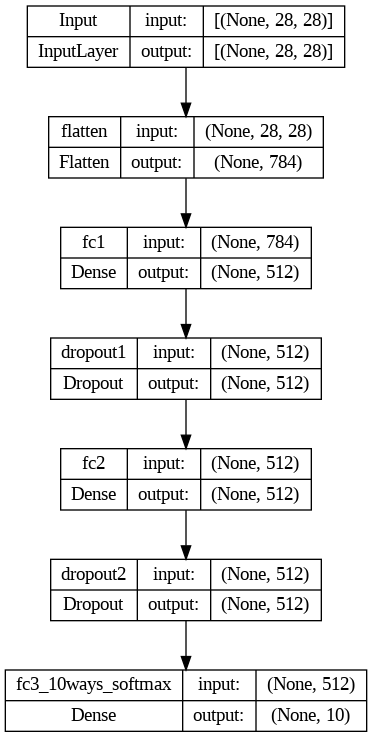

In [10]:
plot_model(model, show_shapes=True)

# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

In [11]:
# declare learning rate, loss function, and model metric
loss = 'categorical_crossentropy'
lr = 0.01
model.compile(loss=loss, optimizer=SGD(lr=lr), metrics=['accuracy'])

# train the model
batch_size = 128
epochs = 30

starting_time = time.time()
history = model.fit(x_train, y_train,
                    validation_data=(x_test, y_test),
                    batch_size=batch_size,
                    epochs=epochs)
print('> training time is %.4f minutes' % ((time.time() - starting_time)/60))

Epoch 1/30
469/469 [==============================] - 8s 5ms/step - loss: 1.2531 - accuracy: 0.6733 - val_loss: 0.5518 - val_accuracy: 0.8681
Epoch 2/30
469/469 [==============================] - 2s 4ms/step - loss: 0.5385 - accuracy: 0.8484 - val_loss: 0.3802 - val_accuracy: 0.8966
Epoch 3/30
469/469 [==============================] - 2s 4ms/step - loss: 0.4264 - accuracy: 0.8769 - val_loss: 0.3245 - val_accuracy: 0.9089
Epoch 4/30
469/469 [==============================] - 2s 4ms/step - loss: 0.3760 - accuracy: 0.8910 - val_loss: 0.2933 - val_accuracy: 0.9159
Epoch 5/30
469/469 [==============================] - 3s 5ms/step - loss: 0.3436 - accuracy: 0.8999 - val_loss: 0.2719 - val_accuracy: 0.9214
Epoch 6/30
469/469 [==============================] - 2s 4ms/step - loss: 0.3178 - accuracy: 0.9082 - val_loss: 0.2551 - val_accuracy: 0.9257
Epoch 7/30
469/469 [==============================] - 2s 4ms/step - loss: 0.2951 - accuracy: 0.9141 - val_loss: 0.2398 - val_accuracy: 0.9302
Epoch 

### Training time
- Training time with GTX 1080 is about 1.4402 minutes for 30 epochs
- Training time with Core i7 is around 3.0493 minutes for 30 epochs

# (4) Evaluate trained model

In [12]:
score = model.evaluate(x_test, y_test)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

313/313 [==============================] - 1s 3ms/step - loss: 0.1143 - accuracy: 0.9648
Test loss: 0.11428852379322052
Test accuracy: 0.9648000001907349


1/1 [==============================] - 0s 81ms/step


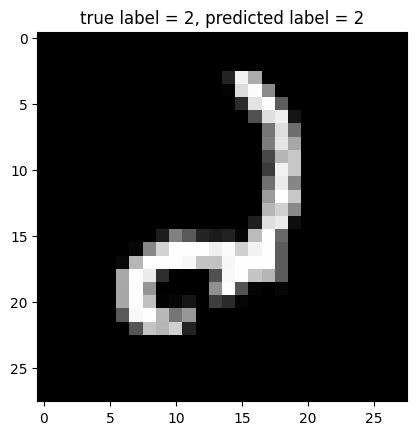

In [13]:
# select a test image randomly
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = np.argmax(y_test[random_test_index])

# predict test image with trained model
pred_label = model.predict(np.expand_dims(test_img, axis=0))
pred_label = np.argmax(pred_label)

plt.imshow(test_img, cmap='gray')
plt.title('true label = %d, predicted label = %d' % (test_label, pred_label))
plt.show()

In [14]:
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = np.argmax(y_test[random_test_index])

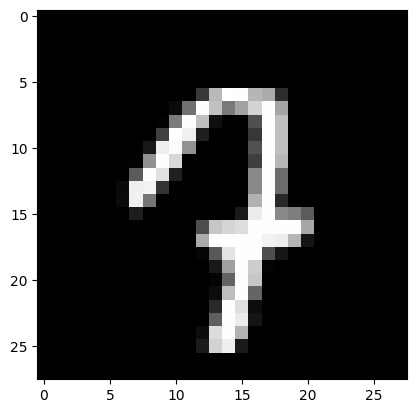

In [15]:
plt.imshow(test_img, cmap='gray')

In [16]:
test_label

7

In [18]:
test_img.shape

(28, 28)

In [20]:
model.input_shape, model.output_shape

((None, 28, 28), (None, 10))

In [22]:
np.expand_dims(test_img, axis = 0).shape

(1, 28, 28)

In [24]:
y_pred = model.predict(np.expand_dims(test_img, axis = 0))

1/1 [==============================] - 0s 31ms/step


In [25]:
y_pred.shape

(1, 10)

In [28]:
np.sum(y_pred, axis = 1)

array([1.0000001], dtype=float32)

In [29]:
np.argmax(y_pred, axis = 1)

array([7])

In [30]:
 model.get_layer("fc2").output

<KerasTensor: shape=(None, 512) dtype=float32 (created by layer 'fc2')>

In [36]:
model1 = Model(inputs = model.input, outputs =  [model.get_layer("fc2").output, model.output])

In [39]:
y_feat, y_pred = model1.predict(np.expand_dims(test_img, axis = 0))

1/1 [==============================] - 0s 32ms/step


In [40]:
y_feat.shape, y_pred.shape

((1, 512), (1, 10))

In [35]:
y_feat

array([[0.        , 0.        , 0.2539244 , 0.71692634, 0.10112986,
        0.        , 0.        , 0.        , 0.        , 0.7632071 ,
        0.        , 0.33989972, 0.        , 0.        , 0.03583318,
        0.        , 0.5479027 , 0.31055835, 0.49080172, 0.03659607,
        0.3069846 , 0.32453215, 0.8680391 , 0.3121356 , 0.        ,
        0.        , 0.42357484, 0.        , 0.        , 0.76415277,
        0.44914567, 1.0079483 , 0.        , 0.        , 0.59302485,
        1.0148873 , 0.01228077, 0.8565107 , 0.09642761, 0.        ,
        0.06789274, 0.02733044, 0.        , 0.60980844, 0.9230026 ,
        0.65816486, 0.03541742, 0.36116457, 0.1910608 , 0.24816366,
        0.29250726, 0.        , 0.3549206 , 0.        , 0.44423646,
        0.08812717, 0.        , 0.18280871, 0.33243468, 0.1820766 ,
        0.89287955, 0.16964018, 0.        , 0.        , 0.6599315 ,
        0.36135823, 0.        , 0.        , 0.67707646, 0.        ,
        0.        , 0.18883961, 0.        , 0.32